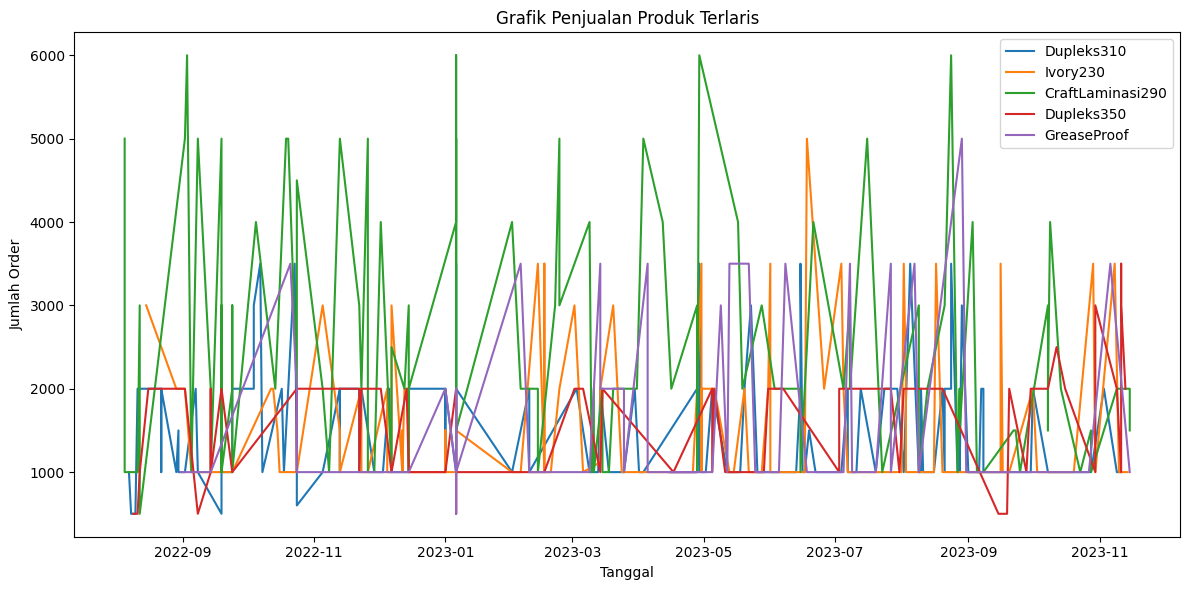

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
sales = pd.read_csv('data_penjualan.csv', sep=';')
sales.columns = sales.columns.str.strip()  # Remove leading/trailing spaces from column names

# Konversi tanggal
sales['Tanggal'] = pd.to_datetime(sales['Tanggal'], dayfirst=True)

# Produk terlaris
top_products = sales['Jenis Produk'].value_counts().nlargest(5).index

plt.figure(figsize=(12, 6))
for prod in top_products:
    prod_sales = sales[sales['Jenis Produk'] == prod]
    plt.plot(prod_sales['Tanggal'], prod_sales['Jumlah Order'], label=prod)

plt.title('Grafik Penjualan Produk Terlaris')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Order')
plt.legend()
plt.tight_layout()
plt.show()

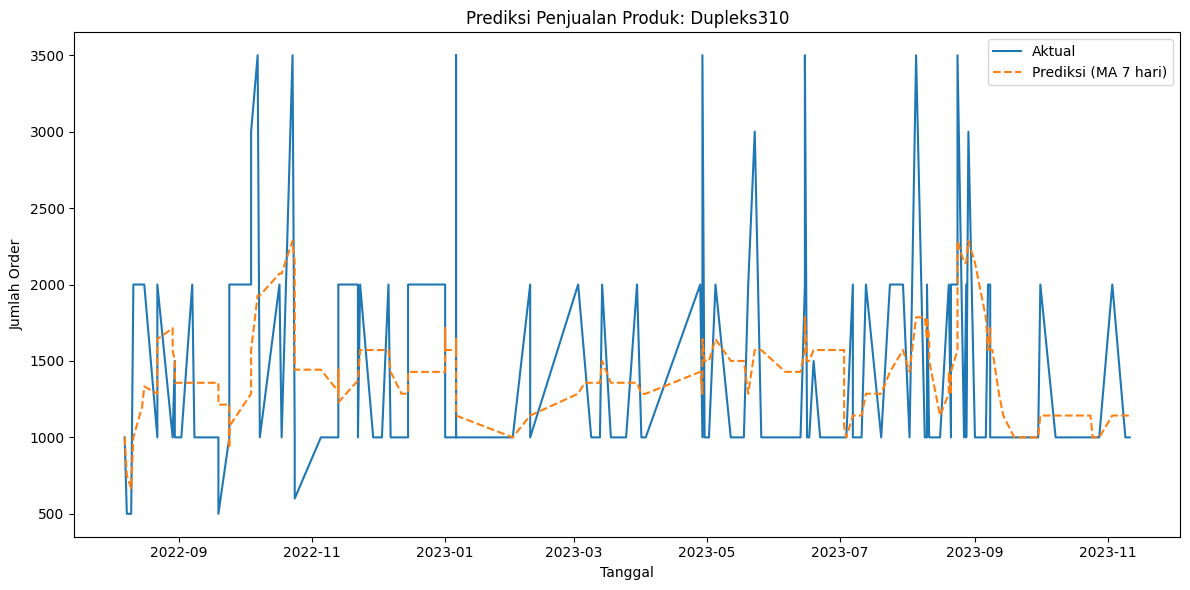

In [7]:
# Pilih satu produk terlaris
prod = top_products[0]
prod_sales = sales[sales['Jenis Produk'] == prod].sort_values('Tanggal')

# Moving average 7 hari
prod_sales['Prediksi'] = prod_sales['Jumlah Order'].rolling(window=7, min_periods=1).mean()

# Hitung total jumlah order dan selisih jumlah order dengan harga
suming = prod_sales['Jumlah Order'].sum()
dellay = prod_sales['Jumlah Order'].sum() - prod_sales['Harga'].sum()

plt.figure(figsize=(12, 6))
plt.plot(prod_sales['Tanggal'], prod_sales['Jumlah Order'], label='Aktual')
plt.plot(prod_sales['Tanggal'], prod_sales['Prediksi'], label='Prediksi (MA 7 hari)', linestyle='--')
plt.title(f'Prediksi Penjualan Produk: {prod}')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Order')
plt.legend()
plt.tight_layout()
plt.show()